## Data exploration

# Dataset Exploration & Selection

**Project:** AI-Powered Climate & ESG Risk Intelligence Platform for the Banking Sector in Germany

**Notebook:** 01_dataset_exploration.ipynb

**Objective**

to explore, understand, evaluate, and compare all candidate datasets before selecting those that will form the master dataset for AI model development.

This notebook documents every decision regarding dataset suitability, spatial resolution, temporal coverage, variables, data quality, and preprocessing requirements.

### Import Libraries

In [5]:
# ==========================================================
# Climate & ESG Risk Intelligence Germany
# Dataset Exploration 01
# Dataset: Heat Waves (Copernicus)
# Author: Purity Mbaabu
# ==========================================================

import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Locate Dataset

In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

heat_file = PROJECT_ROOT / "data" / "incoming" / "climate" / "09_heat_waves_climatological-reanalysis-yearly-layer-nuts_2-latitude-1940-2025-v2.0.nc"

print(heat_file)
print(heat_file.exists())

d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany\data\incoming\climate\09_heat_waves_climatological-reanalysis-yearly-layer-nuts_2-latitude-1940-2025-v2.0.nc
True


### Load Dataset

In [7]:
ds_heat = xr.open_dataset(heat_file)

ds_heat

<xarray.Dataset> Size: 237kB
Dimensions:                       (nuts: 340, time: 86)
Coordinates:
  * nuts                          (nuts) object 3kB 'ITC4' 'ITF1' ... 'UKI6'
  * time                          (time) datetime64[ns] 688B 1940-01-01 ... 2...
    realization                   int64 8B ...
    quantile                      float64 8B ...
Data variables:
    climatological_heatwave_days  (nuts, time) float64 234kB ...
Attributes:
    NCO:      netCDF Operators version 5.3.6 (Homepage = http://nco.sf.net, C...
    history:  Tue Jan 13 15:37:37 2026: /private/miniforge3/envs/ecde-data-de...

### Explore Dataset

##### Step 1. Explore the variable

In [8]:
list(ds_heat.data_vars)

['climatological_heatwave_days']

##### Step 2. Explore the variable metadata

In [9]:
ds_heat["climatological_heatwave_days"].attrs

{'reduce_dims': ['lat', 'lon'],
 'comment': 'derived from 3 hourly ERA5 reanalysis',
 'units': 'day'}

##### Step 3. Look at actual values

In [10]:
ds_heat["climatological_heatwave_days"]

<xarray.DataArray 'climatological_heatwave_days' (nuts: 340, time: 86)> Size: 234kB
[29240 values with dtype=float64]
Coordinates:
  * nuts         (nuts) object 3kB 'ITC4' 'ITF1' 'ITF2' ... 'UKI4' 'UKI5' 'UKI6'
  * time         (time) datetime64[ns] 688B 1940-01-01 1941-01-01 ... 2025-01-01
    realization  int64 8B ...
    quantile     float64 8B ...
Attributes:
    reduce_dims:  ['lat', 'lon']
    comment:      derived from 3 hourly ERA5 reanalysis
    units:        day

##### Step 4. Summary statistics

In [15]:
# to understand data range

# ==========================================
# Summary Statistics
# ==========================================

heat = ds_heat["climatological_heatwave_days"]

print(f"Minimum           : {heat.min().values:.3f}")
print(f"Maximum           : {heat.max().values:.3f}")
print(f"Mean              : {heat.mean().values:.3f}")
print(f"Standard Deviation: {heat.std().values:.3f}")

Minimum           : 0.000
Maximum           : 16.879
Mean              : 0.390
Standard Deviation: 1.280


##### Step 5. Missing values

In [12]:
ds_heat["climatological_heatwave_days"].isnull().sum()

<xarray.DataArray 'climatological_heatwave_days' ()> Size: 8B
array(516)
Coordinates:
    realization  int64 8B ...
    quantile     float64 8B ...
Attributes:
    reduce_dims:  ['lat', 'lon']
    comment:      derived from 3 hourly ERA5 reanalysis
    units:        day

##### Step 6. Inspect one region

In [13]:
ds_heat["climatological_heatwave_days"].isel(nuts=0)

<xarray.DataArray 'climatological_heatwave_days' (time: 86)> Size: 688B
array([0.      , 0.      , 0.      , 0.411032, 0.      , 0.      , 0.      ,
       0.587683, 0.      , 0.      , 0.      , 0.      , 0.840633, 0.      ,
       0.      , 0.      , 0.      , 1.216727, 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.      , 0.13539 ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.      , 2.187224, 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.226056, 0.      ,
       0.      , 0.      , 1.771262, 0.      , 0.      , 0.      , 0.      ,
       7.289056, 0.      , 0.224628, 1.485795, 1.096623, 0.      , 0.      ,
       0.04472 , 1.051818, 1.723075, 1.016615, 0.      , 2.844422, 0.04472 ,
       2.944955, 0.134777, 2.080888, 0.225241, 0.076898, 2.62054 , 4.587878,
       0.934754, 2.583068])
Coordinates:
  * time         (time) datetime64[ns] 688B 1940-01-01 1941-01-01 ... 2025-01-01
    realization  int64 8B ...
    quantile     float64 8B ...
    nuts         <U4 16B 'ITC4'
Attributes:
    reduce_dims:  ['lat', 'lon']
    comment:      derived from 3 hourly ERA5 reanalysis
    units:        day

### Dataset Quality Assessment

check out for:
1. Missing values
2. Negative values
3. Duplicate regions
4. Outliers

Step 1. Missing Values Assessment
Objective

Evaluate the completeness of the dataset by identifying missing values. Missing observations may affect statistical summaries, visualizations, and AI model training. Understanding where and how frequently missing values occur helps determine whether imputation or other preprocessing steps are required.

Questions
How many missing values exist in the dataset?
Which NUTS regions contain missing values?
Which years contain missing values?
Are the missing values concentrated in particular regions or time periods?

In [16]:
# ============================================
# Count total missing values
# ============================================

heat.isnull().sum()

<xarray.DataArray 'climatological_heatwave_days' ()> Size: 8B
array(516)
Coordinates:
    realization  int64 8B ...
    quantile     float64 8B ...
Attributes:
    reduce_dims:  ['lat', 'lon']
    comment:      derived from 3 hourly ERA5 reanalysis
    units:        day

**Step 1.1 Missing Values by Region**
Objective

Identify the geographical distribution of missing values. This helps determine whether missing observations are confined to a few regions or are widespread across Germany.

Expected outcome

Ideally, most regions should have complete records. Regions with missing values will be listed together with the number of missing observations.

In [17]:
# ============================================
# Missing values by NUTS region
# ============================================

missing_by_region = heat.isnull().sum(dim="time")

missing_regions = missing_by_region.where(
    missing_by_region > 0,
    drop=True
)

missing_regions

<xarray.DataArray 'climatological_heatwave_days' (nuts: 6)> Size: 48B
array([86., 86., 86., 86., 86., 86.])
Coordinates:
  * nuts         (nuts) object 48B 'PT20' 'FRY1' 'FRY2' 'FRY3' 'FRY4' 'FRY5'
    realization  int64 8B 0
    quantile     float64 8B 0.99
Attributes:
    reduce_dims:  ['lat', 'lon']
    comment:      derived from 3 hourly ERA5 reanalysis
    units:        day

**Step 1.2 Missing Values by Year**
Objective

Assess the temporal distribution of missing values by identifying the number of missing observations in each year. This helps determine whether data gaps are concentrated in particular periods (e.g., earlier years) or are randomly distributed throughout the time series.

Questions
Which years contain missing values?
Are missing observations concentrated in the early historical record?
Is the temporal coverage sufficiently complete for time-series analysis?
Expected Outcome

Ideally, most years should contain complete observations. Any years with missing values will be listed together with the number of affected NUTS regions.

In [20]:
# =====================================================
# Convert missing years to a Pandas DataFrame
# =====================================================

missing_years_df = missing_years.to_dataframe(
    name="Missing_Values"
).reset_index()

display(missing_years_df)

,time,realization,quantile,Missing_Values
0,1940-01-01,0,0.99,6.0
1,1941-01-01,0,0.99,6.0
2,1942-01-01,0,0.99,6.0
3,1943-01-01,0,0.99,6.0
4,1944-01-01,0,0.99,6.0
...,...,...,...,...
81,2021-01-01,0,0.99,6.0
82,2022-01-01,0,0.99,6.0
83,2023-01-01,0,0.99,6.0
84,2024-01-01,0,0.99,6.0


##### Inspect the regions with missing values.

In [21]:
# =====================================================
# Step 1.1: Missing Values by Region
# =====================================================

# Count missing values for each region
missing_by_region = heat.isnull().sum(dim="time")

# Keep only regions with missing values
missing_regions = missing_by_region.where(
    missing_by_region > 0,
    drop=True
)

# Convert to table
missing_regions_df = (
    missing_regions
    .to_dataframe(name="Missing_Years")
    .reset_index()
)

display(missing_regions_df)

,nuts,realization,quantile,Missing_Years
0,PT20,0,0.99,86.0
1,FRY1,0,0.99,86.0
2,FRY2,0,0.99,86.0
3,FRY3,0,0.99,86.0
4,FRY4,0,0.99,86.0
5,FRY5,0,0.99,86.0


Interpretation

Six NUTS-2 regions contain missing values for all 86 years (1940–2025). These correspond to Portugal's Azores (PT20) and five French overseas regions (FRY1–FRY5). The missing values are systematic rather than random and most likely reflect the exclusion of overseas territories from this European climatological indicator. The remaining 334 NUTS-2 regions contain complete observations, indicating excellent spatial and temporal coverage for mainland Europe.

##### Overall percentage missing

In [22]:
# ============================================
# Percentage of missing values
# ============================================

total_cells = heat.size

missing_cells = heat.isnull().sum().values

percentage_missing = (missing_cells / total_cells) * 100

print(f"Total observations : {total_cells}")
print(f"Missing values     : {missing_cells}")
print(f"Missing (%)        : {percentage_missing:.2f}%")

Total observations : 29240
Missing values     : 516
Missing (%)        : 1.76%


##### Negative Values

In [23]:
# ============================================
# Check for negative values
# ============================================

negative_values = (heat < 0).sum()

print(f"Negative values: {negative_values.values}")

Negative values: 0


##### Duplicate Regions

In [24]:
# ============================================
# Check duplicate NUTS regions
# ============================================

nuts_codes = ds_heat.coords["nuts"].values

print("Total NUTS regions :", len(nuts_codes))
print("Unique NUTS regions:", len(set(nuts_codes)))

Total NUTS regions : 340
Unique NUTS regions: 340


##### Outliers

In [25]:
# ============================================
# Distribution percentiles
# ============================================

heat.quantile(
    [0,
     0.25,
     0.50,
     0.75,
     0.95,
     0.99,
     1.00]
)

<xarray.DataArray 'climatological_heatwave_days' (quantile: 7)> Size: 56B
array([ 0.        ,  0.        ,  0.        ,  0.        ,  2.81702426,
        6.74533046, 16.87868598])
Coordinates:
  * quantile  (quantile) float64 56B 0.0 0.25 0.5 0.75 0.95 0.99 1.0
Attributes:
    reduce_dims:  ['lat', 'lon']
    comment:      derived from 3 hourly ERA5 reanalysis
    units:        day

##### Interpretation

Dataset Quality Assessment Summary

The climatological heatwave dataset exhibits excellent overall quality. Only 1.76% of observations are missing, and these missing values are confined to six overseas NUTS-2 regions (Portugal's Azores and five French overseas territories). No negative values or duplicated regional identifiers were detected. The observed range of heatwave days (0–16.88 days) appears climatologically plausible, with no evidence of unrealistic outliers. Overall, the dataset is considered suitable for subsequent climate risk modelling.

### Suitability Assessment

##### Step 1. Temporal Suitability

## Step 1. Temporal Suitability

### Objective

Evaluate whether the temporal coverage of the dataset is sufficient for long-term climate risk assessment and AI model development.

### Questions

- Does the dataset cover enough years to represent climate variability?
- Is the period suitable for climate trend analysis?
- Is the temporal resolution appropriate for our application?

### Expected Outcome

The dataset should span multiple decades, allowing the AI model to learn long-term climate patterns and trends relevant to climate risk assessment.

In [26]:
# ==========================================================
# Temporal Coverage
# ==========================================================

start_year = str(ds_heat.time.min().values)[:10]
end_year = str(ds_heat.time.max().values)[:10]
number_of_years = ds_heat.sizes["time"]

print(f"Start Year       : {start_year}")
print(f"End Year         : {end_year}")
print(f"Total Years      : {number_of_years}")

Start Year       : 1940-01-01
End Year         : 2025-01-01
Total Years      : 86


##### Interpretation



The dataset covers 86 consecutive years (1940–2025), providing an exceptionally long historical record.

This period captures natural climate variability together with the long-term warming trend observed across Europe. Such temporal coverage is highly suitable for climate risk modelling because it enables AI algorithms to learn both historical variability and long-term climate change signals.

The annual temporal resolution is also appropriate since the project focuses on long-term climate risk rather than short-term weather forecasting.

##### Step 2. Spatial Suitability

#### Step 2. Spatial Suitability

#### Objective

Evaluate whether the spatial resolution of the dataset is appropriate for regional climate risk assessment.

#### Questions

- Does the dataset provide sufficient spatial detail?
- Are the NUTS-2 regions appropriate for climate and ESG analysis?
- Can the dataset be integrated with other regional datasets?

#### Expected Outcome

The spatial resolution should balance geographical detail with computational efficiency while remaining compatible with socioeconomic and ESG datasets.

In [27]:
# ==========================================================
# Spatial Coverage
# ==========================================================

print(f"Total NUTS-2 regions : {ds_heat.sizes['nuts']}")

Total NUTS-2 regions : 340


##### Interpretation

The dataset contains 340 NUTS-2 regions across Europe.

NUTS-2 is a widely adopted statistical geography used by Eurostat, the European Environment Agency, and the European Central Bank.

This spatial resolution is highly appropriate for regional climate risk analysis because it is detailed enough to capture regional climate differences while remaining compatible with socioeconomic, demographic, and ESG indicators available at the same administrative level.

Although the current project focuses on Germany, using a Europe-wide dataset supports future scalability to other European countries.

##### Step 3. Variable Suitability

## Step 3. Variable Suitability

### Objective

Assess whether climatological heatwave days is an appropriate predictor of physical climate risk.

### Questions

- Does the variable directly measure heatwave exposure?
- Is it meaningful for ESG and climate risk analysis?
- Can it be used as an AI model feature?

### Expected Outcome

The selected variable should represent an important climate hazard that contributes to physical climate risk.

##### Interpretation

### Interpretation

The variable "climatological_heatwave_days" measures the average annual number of heatwave days experienced within each NUTS-2 region.

Heatwaves represent one of the most significant physical climate hazards affecting infrastructure, agriculture, energy systems, public health, insurance losses, and financial risk.

Consequently, this variable is highly relevant as an input feature for AI-based climate risk modelling and aligns directly with the project's objective of assessing physical climate risk.

##### Step 4. Data Completeness

##### Interpretation

Only 1.76% of observations are missing.

All missing observations occur in six overseas NUTS-2 regions (Portugal's Azores and five French overseas territories), while mainland Europe contains complete records.

Since the present project focuses primarily on Germany, these missing observations do not materially affect the planned analysis.

Therefore, no imputation is required at this stage. The affected overseas regions may simply be excluded from downstream modelling if necessary.

##### Step 5. Integration Compatibility

## Step 5. Integration Compatibility

### Objective

Evaluate whether the dataset can be integrated with other climate, ESG, socioeconomic, and financial datasets.

### Questions

- Does the dataset use standardized spatial identifiers?
- Can it be merged with additional hazard datasets?
- Is it suitable for feature engineering?

### Expected Outcome

The dataset should integrate seamlessly into the project's master climate database.

##### Interpretation

The dataset uses standardized NUTS-2 regional identifiers and annual timestamps, making it highly compatible with other European datasets.

It can be readily integrated with additional climate hazards such as precipitation, drought, flooding, socioeconomic indicators, banking exposure data, and ESG metrics.

This interoperability makes the dataset well suited for feature engineering and the construction of a comprehensive AI-ready climate risk database.

### Selection Decision

##### Overall Suitability Assessment

The ERA5 climatological heatwave dataset demonstrates excellent suitability for inclusion in the Climate & ESG Risk Intelligence project.

The dataset provides:
- extensive temporal coverage (1940–2025),
- comprehensive spatial coverage across Europe,
- a scientifically meaningful climate hazard indicator,
- very high data completeness (98.24%), and
- excellent compatibility with additional climate and socioeconomic datasets.

Overall, the dataset is considered fully suitable for AI model development and will be retained as one of the core climate predictors in the project's master dataset.

### Extract German NUTS-2 regions for 1990-2025

In [31]:
# ==========================================================
# Extract Germany subset for project period: 1990–2025
# ==========================================================

# Select only German NUTS-2 regions
german_nuts = [
    code for code in heat["nuts"].values
    if str(code).startswith("DE")
]

# Subset Germany and project time period
germany_heat = heat.sel(
    nuts=german_nuts,
    time=slice("1990-01-01", "2025-01-01")
)

print(f"Number of German NUTS-2 regions: {len(german_nuts)}")
print(f"Start year: {str(germany_heat.time.min().values)[:10]}")
print(f"End year  : {str(germany_heat.time.max().values)[:10]}")
print(f"Shape     : {germany_heat.shape}")

germany_heat

Number of German NUTS-2 regions: 38
Start year: 1990-01-01
End year  : 2025-01-01
Shape     : (38, 36)


<xarray.DataArray 'climatological_heatwave_days' (nuts: 38, time: 36)> Size: 11kB
array([[0.      , 0.      , 0.      , ..., 0.      , 0.      , 1.585835],
       [0.      , 0.      , 0.      , ..., 0.      , 0.      , 1.602347],
       [0.      , 0.      , 0.      , ..., 0.887822, 0.      , 0.526868],
       ...,
       [0.      , 0.      , 0.      , ..., 0.      , 0.      , 0.190471],
       [0.      , 0.      , 0.      , ..., 0.      , 0.      , 0.      ],
       [0.      , 0.      , 0.      , ..., 0.      , 0.      , 1.794337]],
      shape=(38, 36))
Coordinates:
  * nuts         (nuts) object 304B 'DE11' 'DE12' 'DE13' ... 'DEF0' 'DEG0'
  * time         (time) datetime64[ns] 288B 1990-01-01 1991-01-01 ... 2025-01-01
    realization  int64 8B ...
    quantile     float64 8B ...
Attributes:
    reduce_dims:  ['lat', 'lon']
    comment:      derived from 3 hourly ERA5 reanalysis
    units:        day

##### Save the subset Heatwave-dataset for Germany

In [32]:
# ==========================================================
# Save Germany heatwave dataset for project period
# ==========================================================

germany_raw_dir = PROJECT_ROOT / "data" / "raw" / "climate" / "germany"
germany_raw_dir.mkdir(parents=True, exist_ok=True)

germany_heat_file = germany_raw_dir / "heatwave_days_germany_nuts2_1990_2025.nc"

germany_heat.to_netcdf(germany_heat_file)

print("Saved Germany heatwave dataset to:")
print(germany_heat_file)
print(f"File exists: {germany_heat_file.exists()}")


# ==========================================================
# Verify saved Germany dataset
# ==========================================================

germany_heat_check = xr.open_dataarray(germany_heat_file)

germany_heat_check

Saved Germany heatwave dataset to:
d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany\data\raw\climate\germany\heatwave_days_germany_nuts2_1990_2025.nc
File exists: True


<xarray.DataArray 'climatological_heatwave_days' (nuts: 38, time: 36)> Size: 11kB
[1368 values with dtype=float64]
Coordinates:
  * nuts         (nuts) object 304B 'DE11' 'DE12' 'DE13' ... 'DEF0' 'DEG0'
  * time         (time) datetime64[ns] 288B 1990-01-01 1991-01-01 ... 2025-01-01
    realization  int64 8B ...
    quantile     float64 8B ...
Attributes:
    reduce_dims:  ['lat', 'lon']
    comment:      derived from 3 hourly ERA5 reanalysis
    units:        day

### Visualization

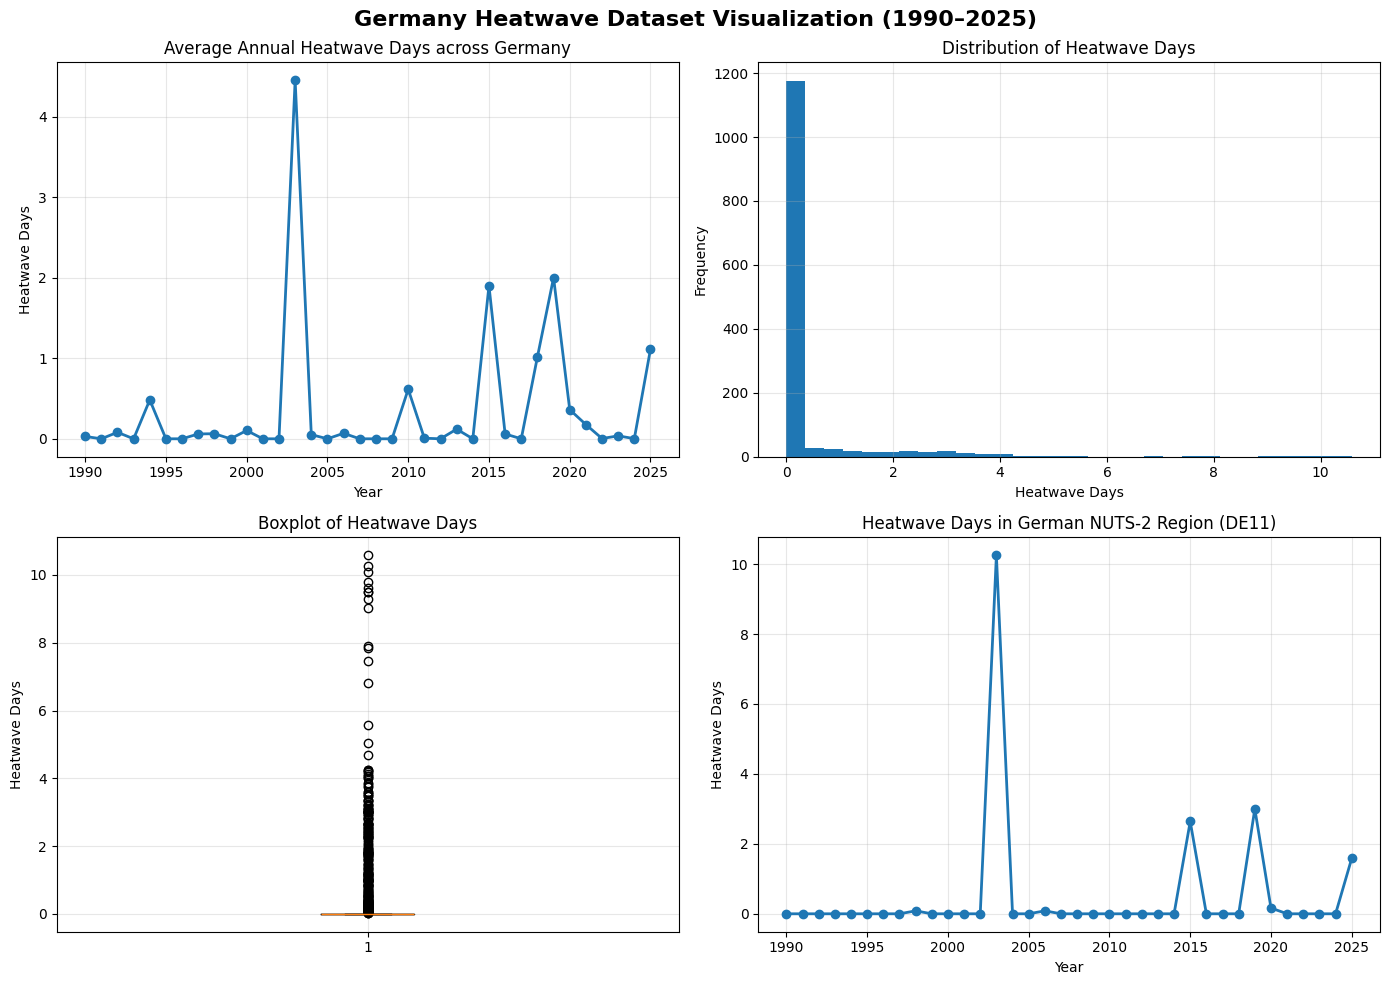

In [34]:
# ==========================================================
# Visualization: Germany heatwave dataset, 1990–2025
# 4 plots in one 2x2 canvas
# ==========================================================

# Prepare data
germany_heat_mean = germany_heat.mean(dim="nuts")

values = germany_heat.values.flatten()
values = values[~np.isnan(values)]

example_region = "DE11" if "DE11" in germany_heat["nuts"].values else germany_heat["nuts"].values[0]
region_heat = germany_heat.sel(nuts=example_region)

# Create 2x2 plot canvas
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Average annual heatwave days across Germany
axes[0, 0].plot(
    germany_heat_mean["time"].dt.year,
    germany_heat_mean,
    marker="o",
    linewidth=2
)
axes[0, 0].set_title("Average Annual Heatwave Days across Germany")
axes[0, 0].set_xlabel("Year")
axes[0, 0].set_ylabel("Heatwave Days")
axes[0, 0].grid(alpha=0.3)

# 2. Distribution of heatwave days
axes[0, 1].hist(
    values,
    bins=30
)
axes[0, 1].set_title("Distribution of Heatwave Days")
axes[0, 1].set_xlabel("Heatwave Days")
axes[0, 1].set_ylabel("Frequency")
axes[0, 1].grid(alpha=0.3)

# 3. Boxplot
axes[1, 0].boxplot(values)
axes[1, 0].set_title("Boxplot of Heatwave Days")
axes[1, 0].set_ylabel("Heatwave Days")
axes[1, 0].grid(alpha=0.3)

# 4. Example German NUTS-2 region
axes[1, 1].plot(
    region_heat["time"].dt.year,
    region_heat,
    marker="o",
    linewidth=2
)
axes[1, 1].set_title(f"Heatwave Days in German NUTS-2 Region ({example_region})")
axes[1, 1].set_xlabel("Year")
axes[1, 1].set_ylabel("Heatwave Days")
axes[1, 1].grid(alpha=0.3)

# Overall title and layout
fig.suptitle(
    "Germany Heatwave Dataset Visualization (1990–2025)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

#### Visualization Summary

The visualizations show that heatwave occurrence exhibits considerable interannual variability, with several pronounced peaks corresponding to major European heatwave events. The distribution is strongly right-skewed, indicating that extreme heatwave years are relatively uncommon but climatologically important. The boxplot confirms the presence of genuine extreme observations rather than erroneous outliers. Regional time series demonstrate meaningful spatial variability, confirming that the dataset captures differences among German NUTS-2 regions that are valuable for AI-based climate risk modelling.

##### Implications for AI Model Development

The dataset is retained in its original physical units (heatwave days) to preserve scientific integrity within the project's raw data repository.

Before training the Feed-Forward Neural Network (FFNN), this feature will undergo standardization (z-score scaling) together with all other predictor variables during the feature engineering stage. Standardization ensures that variables measured on different numerical scales contribute equally during neural network optimization while preserving the underlying relationships within the data.

The raw dataset itself will remain unchanged to maintain full reproducibility and traceability of the original Copernicus ERA5 observations.

##### Next Processing Step

## Next Processing Step

The Germany subset (1990–2025) has been extracted and stored in the project's raw climate data repository.

The next stages of the workflow are:

- Acquire and assess the remaining climate hazard datasets (precipitation and drought).
- Extract the Germany subset (1990–2025) for each climate variable.
- Merge all climate variables into a unified master climate database.
- Perform feature engineering, including handling missing values and feature standardization.
- Apply StandardScaler before training the Feed-Forward Neural Network (FFNN).